# Yeni gecikme modeline geçelim mi?

Operasyon ekibi aynı 240 sipariş için eski A ve yeni B modelinin kararlarını karşılaştırıyor. Gecikmeyi kaçırmak yanlış alarmdan 10 kat maliyetli varsayılıyor. İki modelin doğruluğunu bağımsız iki oran gibi test etmek aynı siparişlerin ortak zorluğunu kaybeder. Daha yüksek toplam doğruluk, daha düşük hata maliyeti demek olmayabilir.

**Karar:** B modelini hangi sabit eşikle değerlendirmeye devam etmeliyiz; doğruluk farkı ve kaçırma yükü ne söylüyor?

**Birim:** Bağımsız birim: test siparişi. Eş: aynı siparişte A/B doğru-yanlış göstergeleri.

**Yöntem:** Önce aynı siparişlerde iki doğruluk göstergesi oluştur. Uyumsuz iki hücre McNemar’ın girdisidir. İki yönlü tam test binom referansını kullanır. Sonra doğruluk farkını, gerçek pozitif sayısını ve hata maliyetini ayrı raporla.

Veriler sabit tohumla üretilmiş sentetiktir; gerçek şirket veya kişi verisi değildir. Python paket sürümleri ZIP içindeki requirements.txt dosyasındadır. Her senaryo kendi verisini üretir; CSV dosyaları hazır örneklerle birlikte verilir.


## Senaryo: Her iki eşik .50

Önce beklediğin sonucu yaz. Aşağıdaki hücre analizin tamamını içerir; seçilmiş senaryoyu değiştirip yeniden çalıştırabilirsin.


                           Ölçü         Değer
                 A / B doğruluk 77.9% / 91.7%
B−A doğruluk farkı · yüzde puan         13.75
        McNemar iki yönlü tam p      0.000027
               Uyumsuz çift b+c            61
                         B eşik           0.5

Hata ve maliyet karşılaştırması
model  threshold  TP  FP  FN  TN  accuracy  cost_per_1000
    A        0.5  27  43  10 160  0.779167     595.833333
    B        0.5  32  15   5 188  0.916667     270.833333

Eşli bootstrap doğruluk farkı aralığı · oran
 lower    upper
 0.075 0.195833

Karar: McNemar p=2.7192e-05; karar yalnız doğruluğa bırakılmaz. Bu senaryoda A maliyeti 595.8, B maliyeti 270.8 puan/1.000 kayıt. Kaçırma maliyeti 10, yanlış alarm maliyeti 1 varsayımı açıkça korunmalı.

Sınır: Bağımsız test siparişleri, aynı kayıtlarda iki model ve sabit eşikler. Puanlar sentetik olup kalibre olasılık kanıtı değildir. Final test üzerinde eşiği seçip aynı sonucu tarafsız başarı sayma; eşik senaryoları öğretim içindir.

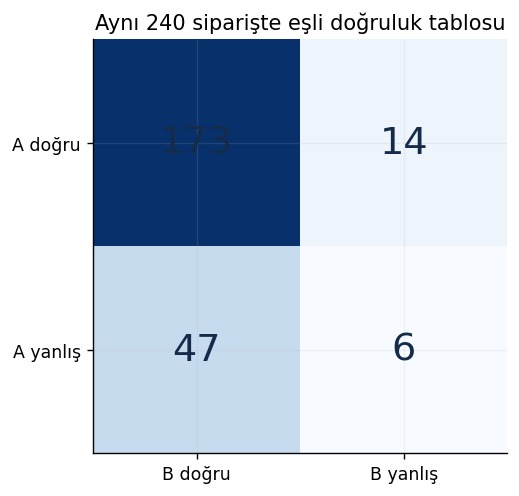

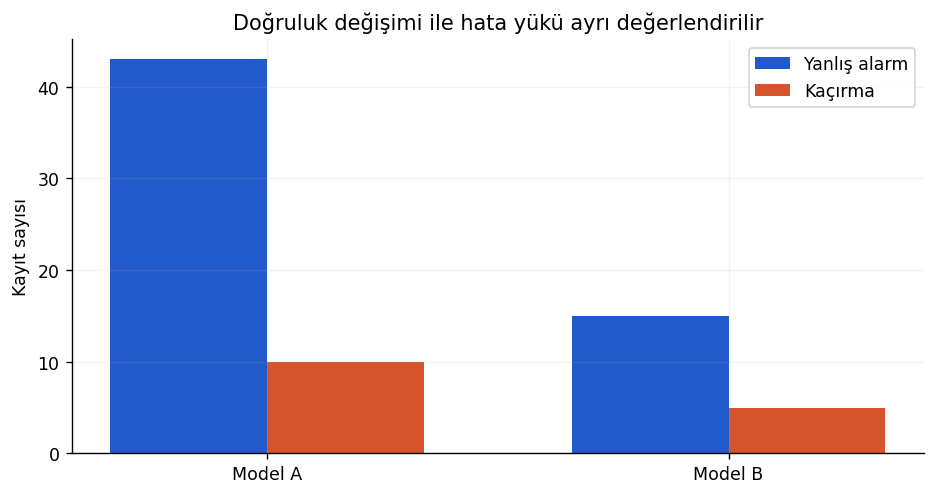

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
plt.rcParams.update({'figure.figsize':(8.8,4.3),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

def tbl(df,title):return {'title':title,'columns':[str(c) for c in df.columns],'rows':df.where(pd.notnull(df),None).values.tolist()}

def model_pairs(scenario='default'):
 rng=np.random.default_rng(260802);n=240;y=rng.binomial(1,.16,n);difficulty=rng.normal(0,.7,n);score_a=special.expit((2*y-1)*1.05+difficulty+rng.normal(0,1,n));score_b=special.expit((2*y-1)*1.4+difficulty+rng.normal(0,.9,n));threshold=.5 if scenario=='default' else .35;pa=score_a>=.5;pb=score_b>=threshold;ca=pa==y;cb=pb==y
 table=np.array([[np.sum(ca&cb),np.sum(ca&~cb)],[np.sum(~ca&cb),np.sum(~ca&~cb)]]);test=mcnemar(table,exact=True);b,c=table[0,1],table[1,0];manual=1. if b+c==0 else min(1.,2*stats.binom.cdf(min(b,c),b+c,.5));assert np.isclose(test.pvalue,manual,atol=1e-12)
 def metrics(pred):
  tp=np.sum(pred&(y==1));fp=np.sum(pred&(y==0));fn=np.sum(~pred&(y==1));tn=np.sum(~pred&(y==0));return[tp,fp,fn,tn,np.mean(pred==y),(fp+10*fn)/len(y)*1000]
 ma,mb=metrics(pa),metrics(pb);comparison=pd.DataFrame([['A',.5,*ma],['B',threshold,*mb]],columns=['model','threshold','TP','FP','FN','TN','accuracy','cost_per_1000']);delta=cb.astype(int)-ca.astype(int);boot=np.mean(rng.choice(delta,(1500,n),replace=True),axis=1);ci=np.quantile(boot,[.025,.975]);raw=pd.DataFrame({'record_id':np.arange(1,n+1),'actual_late':y,'score_a':score_a,'score_b':score_b})
 fig,ax=plt.subplots();im=ax.imshow(table,cmap='Blues');ax.set(xticks=[0,1],xticklabels=['B doğru','B yanlış'],yticks=[0,1],yticklabels=['A doğru','A yanlış'],title='Aynı 240 siparişte eşli doğruluk tablosu')
 for i in range(2):
  for j in range(2):ax.text(j,i,str(table[i,j]),ha='center',va='center',fontsize=22,color='#142C49')
 fig2,ax2=plt.subplots();x=np.arange(2);ax2.bar(x-.17,[ma[1],mb[1]],.34,label='Yanlış alarm',color='#235ACB');ax2.bar(x+.17,[ma[2],mb[2]],.34,label='Kaçırma',color='#D5542B');ax2.set(xticks=x,xticklabels=['Model A','Model B'],ylabel='Kayıt sayısı',title='Doğruluk değişimi ile hata yükü ayrı değerlendirilir');ax2.legend()
 decision=f'McNemar p={test.pvalue:.5g}; karar yalnız doğruluğa bırakılmaz. Bu senaryoda A maliyeti {ma[-1]:.1f}, B maliyeti {mb[-1]:.1f} puan/1.000 kayıt. Kaçırma maliyeti 10, yanlış alarm maliyeti 1 varsayımı açıkça korunmalı.'
 return dict(metrics={'A / B doğruluk':f'{ma[4]:.1%} / {mb[4]:.1%}','B−A doğruluk farkı · yüzde puan':100*delta.mean(),'McNemar iki yönlü tam p':test.pvalue,'Uyumsuz çift b+c':int(b+c),'B eşik':threshold},tables=[tbl(comparison,'Hata ve maliyet karşılaştırması'),tbl(pd.DataFrame({'lower':[ci[0]],'upper':[ci[1]]}),'Eşli bootstrap doğruluk farkı aralığı · oran')],figures=[('McNemar yalnız iki uyumsuz hücreyi kullanır; bütün doğruları bağımsız iki grup saymaz.',fig),('Eşik düşürülünce alarm ve kaçırma yükleri farklı değişebilir.',fig2)],frames={'ayni_siparisler':raw},steps=['A ve B aynı siparişler üzerinde değerlendirildi; doğruluk göstergelerini çift olarak eşleştir.',f'A doğru/B yanlış={b}; A yanlış/B doğru={c}. H0 altında {b+c} uyumsuz çiftin yönünü p=.5 binom ile karşılaştır.','İki yönlü tam p=2×küçük kuyruk (en çok 1). Ardından doğal farkı, alt sınıf hatalarını ve önceden seçilmiş maliyeti raporla.'],decision=decision,diagnostics={'table':table.tolist(),'exact_p':test.pvalue,'manual_p':manual,'accuracy_difference':delta.mean(),'bootstrap_ci':ci.tolist(),'n':n},limit='Bağımsız test siparişleri, aynı kayıtlarda iki model ve sabit eşikler. Puanlar sentetik olup kalibre olasılık kanıtı değildir. Final test üzerinde eşiği seçip aynı sonucu tarafsız başarı sayma; eşik senaryoları öğretim içindir.')

result=model_pairs('default')
print(pd.DataFrame(list(result['metrics'].items()),columns=['Olcu','Deger']).to_string(index=False))
for t in result['tables']: print(t['title']); print(pd.DataFrame(t['rows'],columns=t['columns']).to_string(index=False))
print('Karar:', result['decision']); print('Sinir:',result['limit'])
for caption,fig in result['figures']: print(caption); plt.show()


## Senaryo: B eşik .35: daha çok alarm

Önce beklediğin sonucu yaz. Aşağıdaki hücre analizin tamamını içerir; seçilmiş senaryoyu değiştirip yeniden çalıştırabilirsin.


                           Ölçü         Değer
                 A / B doğruluk 77.9% / 80.4%
B−A doğruluk farkı · yüzde puan           2.5
        McNemar iki yönlü tam p      0.561381
               Uyumsuz çift b+c            74
                         B eşik          0.35

Hata ve maliyet karşılaştırması
model  threshold  TP  FP  FN  TN  accuracy  cost_per_1000
    A       0.50  27  43  10 160  0.779167     595.833333
    B       0.35  35  45   2 158  0.804167     270.833333

Eşli bootstrap doğruluk farkı aralığı · oran
    lower    upper
-0.045833 0.091667

Karar: McNemar p=0.56138; karar yalnız doğruluğa bırakılmaz. Bu senaryoda A maliyeti 595.8, B maliyeti 270.8 puan/1.000 kayıt. Kaçırma maliyeti 10, yanlış alarm maliyeti 1 varsayımı açıkça korunmalı.

Sınır: Bağımsız test siparişleri, aynı kayıtlarda iki model ve sabit eşikler. Puanlar sentetik olup kalibre olasılık kanıtı değildir. Final test üzerinde eşiği seçip aynı sonucu tarafsız başarı sayma; eşik senaryoları öğretim içind

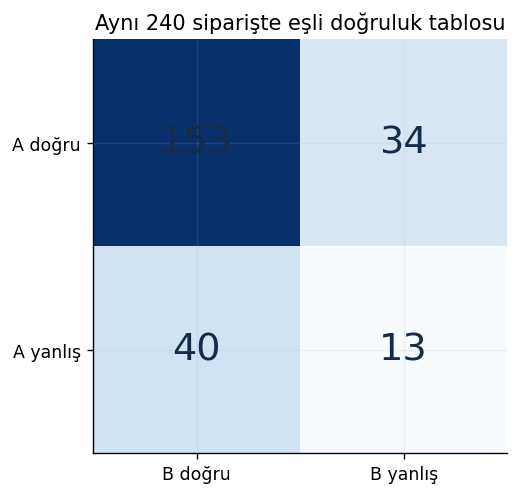

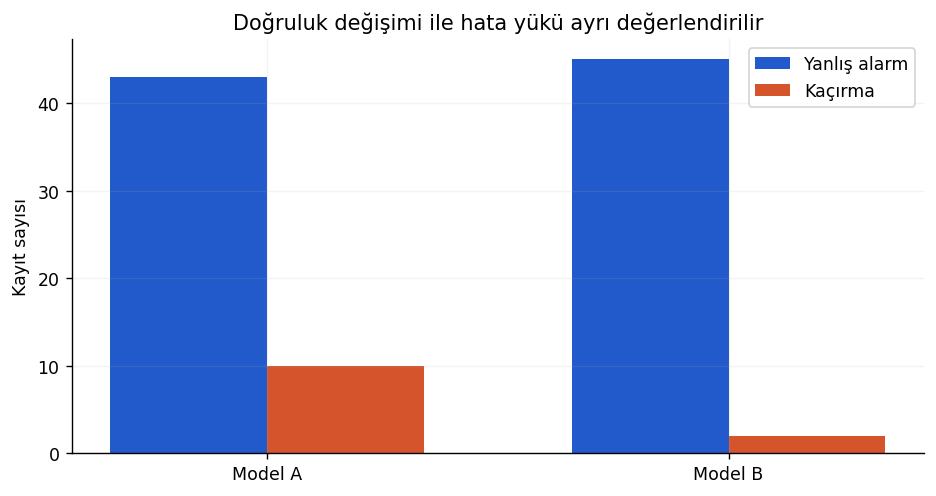

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
plt.rcParams.update({'figure.figsize':(8.8,4.3),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

def tbl(df,title):return {'title':title,'columns':[str(c) for c in df.columns],'rows':df.where(pd.notnull(df),None).values.tolist()}

def model_pairs(scenario='default'):
 rng=np.random.default_rng(260802);n=240;y=rng.binomial(1,.16,n);difficulty=rng.normal(0,.7,n);score_a=special.expit((2*y-1)*1.05+difficulty+rng.normal(0,1,n));score_b=special.expit((2*y-1)*1.4+difficulty+rng.normal(0,.9,n));threshold=.5 if scenario=='default' else .35;pa=score_a>=.5;pb=score_b>=threshold;ca=pa==y;cb=pb==y
 table=np.array([[np.sum(ca&cb),np.sum(ca&~cb)],[np.sum(~ca&cb),np.sum(~ca&~cb)]]);test=mcnemar(table,exact=True);b,c=table[0,1],table[1,0];manual=1. if b+c==0 else min(1.,2*stats.binom.cdf(min(b,c),b+c,.5));assert np.isclose(test.pvalue,manual,atol=1e-12)
 def metrics(pred):
  tp=np.sum(pred&(y==1));fp=np.sum(pred&(y==0));fn=np.sum(~pred&(y==1));tn=np.sum(~pred&(y==0));return[tp,fp,fn,tn,np.mean(pred==y),(fp+10*fn)/len(y)*1000]
 ma,mb=metrics(pa),metrics(pb);comparison=pd.DataFrame([['A',.5,*ma],['B',threshold,*mb]],columns=['model','threshold','TP','FP','FN','TN','accuracy','cost_per_1000']);delta=cb.astype(int)-ca.astype(int);boot=np.mean(rng.choice(delta,(1500,n),replace=True),axis=1);ci=np.quantile(boot,[.025,.975]);raw=pd.DataFrame({'record_id':np.arange(1,n+1),'actual_late':y,'score_a':score_a,'score_b':score_b})
 fig,ax=plt.subplots();im=ax.imshow(table,cmap='Blues');ax.set(xticks=[0,1],xticklabels=['B doğru','B yanlış'],yticks=[0,1],yticklabels=['A doğru','A yanlış'],title='Aynı 240 siparişte eşli doğruluk tablosu')
 for i in range(2):
  for j in range(2):ax.text(j,i,str(table[i,j]),ha='center',va='center',fontsize=22,color='#142C49')
 fig2,ax2=plt.subplots();x=np.arange(2);ax2.bar(x-.17,[ma[1],mb[1]],.34,label='Yanlış alarm',color='#235ACB');ax2.bar(x+.17,[ma[2],mb[2]],.34,label='Kaçırma',color='#D5542B');ax2.set(xticks=x,xticklabels=['Model A','Model B'],ylabel='Kayıt sayısı',title='Doğruluk değişimi ile hata yükü ayrı değerlendirilir');ax2.legend()
 decision=f'McNemar p={test.pvalue:.5g}; karar yalnız doğruluğa bırakılmaz. Bu senaryoda A maliyeti {ma[-1]:.1f}, B maliyeti {mb[-1]:.1f} puan/1.000 kayıt. Kaçırma maliyeti 10, yanlış alarm maliyeti 1 varsayımı açıkça korunmalı.'
 return dict(metrics={'A / B doğruluk':f'{ma[4]:.1%} / {mb[4]:.1%}','B−A doğruluk farkı · yüzde puan':100*delta.mean(),'McNemar iki yönlü tam p':test.pvalue,'Uyumsuz çift b+c':int(b+c),'B eşik':threshold},tables=[tbl(comparison,'Hata ve maliyet karşılaştırması'),tbl(pd.DataFrame({'lower':[ci[0]],'upper':[ci[1]]}),'Eşli bootstrap doğruluk farkı aralığı · oran')],figures=[('McNemar yalnız iki uyumsuz hücreyi kullanır; bütün doğruları bağımsız iki grup saymaz.',fig),('Eşik düşürülünce alarm ve kaçırma yükleri farklı değişebilir.',fig2)],frames={'ayni_siparisler':raw},steps=['A ve B aynı siparişler üzerinde değerlendirildi; doğruluk göstergelerini çift olarak eşleştir.',f'A doğru/B yanlış={b}; A yanlış/B doğru={c}. H0 altında {b+c} uyumsuz çiftin yönünü p=.5 binom ile karşılaştır.','İki yönlü tam p=2×küçük kuyruk (en çok 1). Ardından doğal farkı, alt sınıf hatalarını ve önceden seçilmiş maliyeti raporla.'],decision=decision,diagnostics={'table':table.tolist(),'exact_p':test.pvalue,'manual_p':manual,'accuracy_difference':delta.mean(),'bootstrap_ci':ci.tolist(),'n':n},limit='Bağımsız test siparişleri, aynı kayıtlarda iki model ve sabit eşikler. Puanlar sentetik olup kalibre olasılık kanıtı değildir. Final test üzerinde eşiği seçip aynı sonucu tarafsız başarı sayma; eşik senaryoları öğretim içindir.')

result=model_pairs('sensitive')
print(pd.DataFrame(list(result['metrics'].items()),columns=['Olcu','Deger']).to_string(index=False))
for t in result['tables']: print(t['title']); print(pd.DataFrame(t['rows'],columns=t['columns']).to_string(index=False))
print('Karar:', result['decision']); print('Sinir:',result['limit'])
for caption,fig in result['figures']: print(caption); plt.show()


## Uygula ve karar notu

B eşiği .35 senaryosunda doğruluk ile maliyetin aynı yönde değişip değişmediğini kontrol et. Eşiğin final testten seçilemeyeceğini karar notunda belirt.

Kabul ölçütleri: analiz birimini doğru tanımla; yöntem seçimini gerekçelendir; etkiyi/aralığı doğal birimle raporla; varsayımı ve bir sonraki veri ihtiyacını yaz.
